[Megnyitás a Google Colabban](https://colab.research.google.com/github/ComplexSystemsIntelligence/biztonsagkritikus-rendszerek/blob/main/gyakorlat/notebookok/07_rbd_hid_mc.ipynb) · *Biztonságkritikus rendszerek – gyakorlati útmutató* · © 2026 Abonyi János, Pannon Egyetem · kód: MIT, szöveg: CC BY-NC-SA 4.0

# 7. gyakorlat – blokkdiagramok: hídkapcsolás, Monte Carlo, közös okú meghibásodás

A notebook a könyv 9. fejezetének számításait reprodukálja: a hídkapcsolás megbízhatóságát háromféleképpen (állapotfelsorolás, dekompozíció, minimális utak), a bizonytalan komponensadatok hatását Monte Carlo-szimulációval, végül a közös okú meghibásodás hatását az 1oo2 struktúrára.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
PE = {"kek": "#285780", "sotet": "#1B3A57", "kiemel": "#E07B39", "zold": "#3E8E63", "piros": "#B83A3A", "lila": "#7A5C99", "szurke": "#6B7280"}
plt.rcParams.update({"figure.figsize": (7.5, 4.2), "axes.grid": True, "grid.color": "#e6e9ee", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.prop_cycle": plt.cycler(color=list(PE.values())), "axes.formatter.use_locale": False})
def hu(x, sig=3):
    """Szám magyar formátumban (tizedesvessző, normálalak)."""
    if x == 0: return "0"
    e = int(np.floor(np.log10(abs(x))))
    if -2 <= e < 5: return f"{x:.{max(0, sig-1-e)}f}".replace(".", ",")
    return f"{x/10**e:.{sig-1}f}".replace(".", ",") + f"·10^{e}"
import itertools

In [2]:
# Hídkapcsolás: A–D és C–B a két ág, E a híd; minimális utak
utak = [{"A", "D"}, {"C", "B"}, {"A", "E", "B"}, {"C", "E", "D"}]
elemek = ["A", "B", "C", "D", "E"]
def R_felsorolas(p):
    ossz = 0
    for allapot in itertools.product([0, 1], repeat=5):
        mukodik = {e for e, s in zip(elemek, allapot) if s}
        if any(u <= mukodik for u in utak):
            ossz += np.prod([p[e] if s else 1-p[e] for e, s in zip(elemek, allapot)])
    return ossz
def R_dekompozicio(p):
    # E működik: (A||C) soros (D||B); E hibás: (A–D) || (C–B)
    Rjo = (1-(1-p["A"])*(1-p["C"])) * (1-(1-p["D"])*(1-p["B"]))
    Rrossz = 1 - (1 - p["A"]*p["D"])*(1 - p["C"]*p["B"])
    return p["E"]*Rjo + (1-p["E"])*Rrossz
p = {e: 0.9 for e in elemek}
print("állapotfelsorolás:", round(R_felsorolas(p), 5), " dekompozíció:", round(R_dekompozicio(p), 5))

állapotfelsorolás: 0.97848  dekompozíció: 0.97848


Mindkét módszer $R = 0{,}97848$-at ad, egyezésben a könyvvel. **1. feladat:** számold ki a megbízhatóságot a minimális utak szita-formulájával is!

## Bizonytalan komponensadatok

Tegyük fel, hogy minden elem megbízhatósága bizonytalan: béta-eloszlású, várható értéke 0,9, és a 90%-os tartománya nagyjából 0,85–0,95. Az intervallumbecslés (mindegyik a korlátján) és a Monte Carlo-szimuláció összevetése:

elemszintű 90 %-os tartomány: 0.847 – 0.944
intervallumbecslés: 0.94840 – 0.99346
Monte Carlo: átlag 0.97853, 5–95 %: 0.96689 – 0.98771


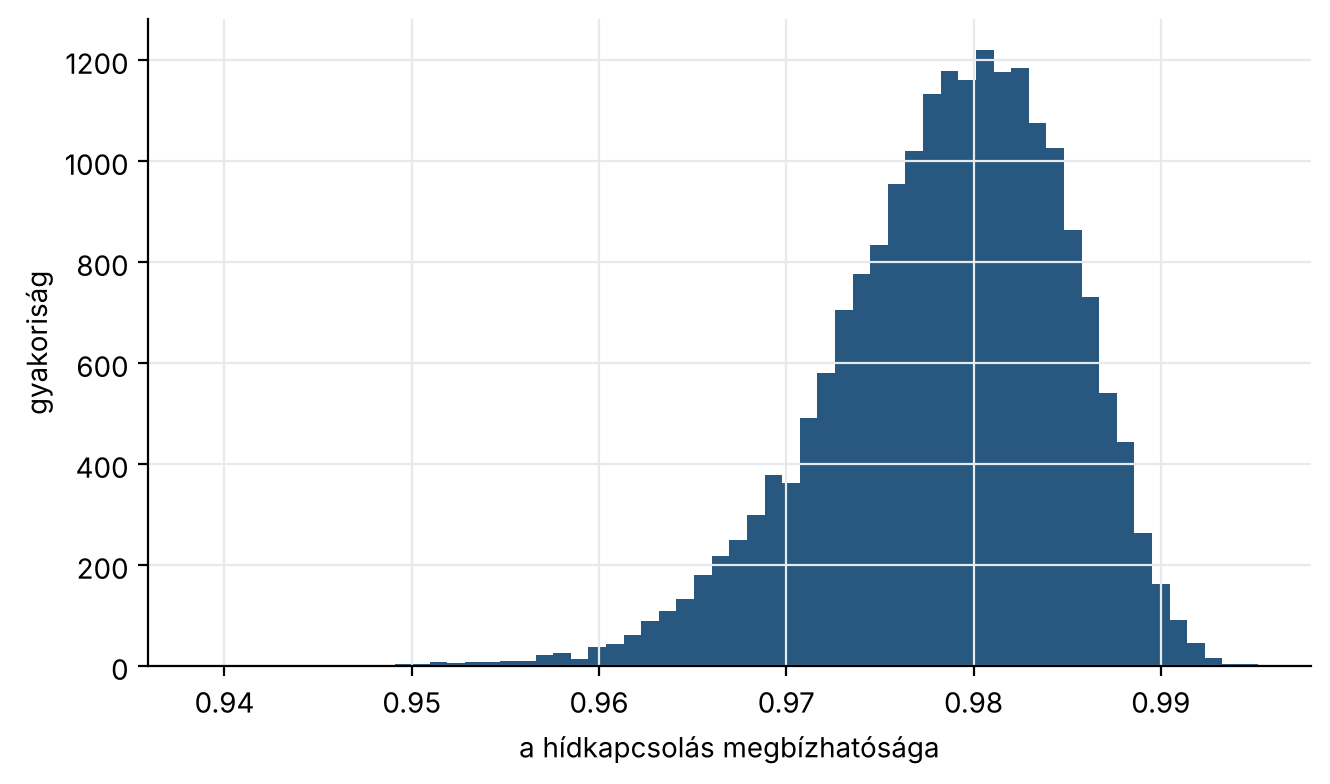

In [3]:
rng = np.random.default_rng(1)
a, b = 90, 10          # Béta(90, 10): várható érték 0,9
minta = rng.beta(a, b, size=(20000, 5))
Rmc = np.array([R_dekompozicio(dict(zip(elemek, s))) for s in minta])
lo, hi = stats.beta.ppf([0.05, 0.95], a, b)
print(f"elemszintű 90 %-os tartomány: {lo:.3f} – {hi:.3f}")
print(f"intervallumbecslés: {R_dekompozicio(dict.fromkeys(elemek, lo)):.5f} – {R_dekompozicio(dict.fromkeys(elemek, hi)):.5f}")
print(f"Monte Carlo: átlag {Rmc.mean():.5f}, 5–95 %: {np.percentile(Rmc, 5):.5f} – {np.percentile(Rmc, 95):.5f}")
plt.hist(Rmc, bins=60, color=PE["kek"]); plt.xlabel("a hídkapcsolás megbízhatósága"); plt.ylabel("gyakoriság"); plt.show()

A Monte Carlo-intervallum szűkebb, mert nem feltételezi, hogy minden elem egyszerre a legrosszabb értékén van.

## Közös okú meghibásodás az 1oo2 struktúrában

Két szelep, $\lambda = 2{,}5\cdot10^{-6}$/h, egy év küldetési idő, javítás nélkül. A β-tényezős modellben a ráta $\beta$ hányada mindkét elemet egyszerre éri.

In [4]:
lam, t = 2.5e-6, 8760
for beta_ in (0, 0.02, 0.05, 0.10, 0.20):
    Rf = np.exp(-(1-beta_)*lam*t); Rc = np.exp(-beta_*lam*t)
    F = 1 - Rc*(1 - (1-Rf)**2)
    print(f"β = {beta_:4.2f}: a két szelep együttes meghibásodásának valószínűsége {hu(F)}")

β = 0.00: a két szelep együttes meghibásodásának valószínűsége 4,69·10^-4
β = 0.02: a két szelep együttes meghibásodásának valószínűsége 8,89·10^-4
β = 0.05: a két szelep együttes meghibásodásának valószínűsége 1,52·10^-3
β = 0.10: a két szelep együttes meghibásodásának valószínűsége 2,57·10^-3
β = 0.20: a két szelep együttes meghibásodásának valószínűsége 4,67·10^-3


**2. feladat.** Mekkora β mellett lesz az 1oo2 struktúra rosszabb, mint a független feltevéssel számolt érték tízszerese? Mit jelent ez a redundancia értékére?

## Mintaprompt

*„Egy hídkapcsolású rendszer megbízhatóságát dekompozícióval számoltam. Kérlek, ellenőrizd a gondolatmenetet lépésenként, és mutasd meg, hogyan kapnám ugyanezt a minimális utakból a szita-formulával! Ne adj meg végeredményt, amíg nem kérem.”*